# Adapted multicoil D5-C5 Cascade CNN across acceleration rates

This notebook reports the completed **2×, 4×, 6×, and 8×** experiments. Each
model was trained independently for **50 epochs / 9,700 updates**. Epochs 10,
20, 30, 40, and 50 were screened on validation data, and one selected checkpoint
per rate was evaluated on the held-out test split.

The five independent D5 residual CNN cascades match the published architecture.
The original single-image Fourier replacement is replaced by a fixed 10-iteration
CG-SENSE proximal solve for raw multicoil measurements, so this is an **adapted
multicoil D5-C5**, rather than an exact reproduction.

References: [paper](https://arxiv.org/abs/1703.00555) ·
[official repository](https://github.com/js3611/Deep-MRI-Reconstruction)

In [1]:
from pathlib import Path
from html import escape
import json, re
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RATES = (2, 4, 6, 8)
RUNS = {rate: Path(f'/data/david_agyei/nyu-dataset/derived/multicoil_cascade_cnn_{rate}x')
        for rate in RATES}

def read_json(path): return json.loads(Path(path).read_text())
def show_table(rows, columns, precision=4, bold_best=None):
    bold_best = bold_best or {}
    best = {}
    for key, direction in bold_best.items():
        values = [row[key] for row in rows if isinstance(row[key], (int, float)) and np.isfinite(row[key])]
        best[key] = (max if direction == 'max' else min)(values)
    def render(value): return f'{value:.{precision}f}' if isinstance(value, float) else escape(str(value))
    header = ''.join(f'<th style="text-align:left;padding:4px 10px">{escape(label)}</th>' for key, label in columns)
    def cell(row, key):
        value = render(row[key])
        if key in best and np.isclose(row[key], best[key]): value = f'<strong>{value}</strong>'
        return f'<td style="padding:4px 10px">{value}</td>'
    body = ''.join('<tr>' + ''.join(cell(row, key) for key, label in columns) + '</tr>' for row in rows)
    display(HTML(f'<table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>'))

selections = {rate: read_json(RUNS[rate]/'evaluation/best_validation_checkpoint.json')
              for rate in RATES}
test_dirs = {rate: RUNS[rate]/'evaluation/test'/f"step-{selections[rate]['checkpoint_step']:07d}"
             for rate in RATES}
tests = {rate: read_json(test_dirs[rate]/'summary.json') for rate in RATES}
selection, test_dir, test = selections[4], test_dirs[4], tests[4]
rdbm = read_json(Path('/data/david_agyei/nyu-dataset/derived/rdbm_full_bf16/evaluation/test/step-0094900/summary.json'))
unrolled = read_json(Path('/data/david_agyei/nyu-dataset/derived/unrolled_rdbm_4x_scratch/evaluation/test/step-0037960/summary.json'))
modl = read_json(Path('/data/david_agyei/nyu-dataset/derived/modl_4x_fp32/evaluation/test/step-0037960/summary.json'))
progression = read_json(ROOT/'results/cascade_cnn_evaluation/qualitative/cascade_progression.json')
print('Selected checkpoints: ' + ', '.join(
    f"{rate}× epoch {selections[rate]['completed_epochs']} (step {selections[rate]['checkpoint_step']:,})"
    for rate in RATES))

Selected checkpoints: 2× epoch 40 (step 7,760), 4× epoch 50 (step 9,700), 6× epoch 50 (step 9,700), 8× epoch 50 (step 9,700)


## Training trajectory

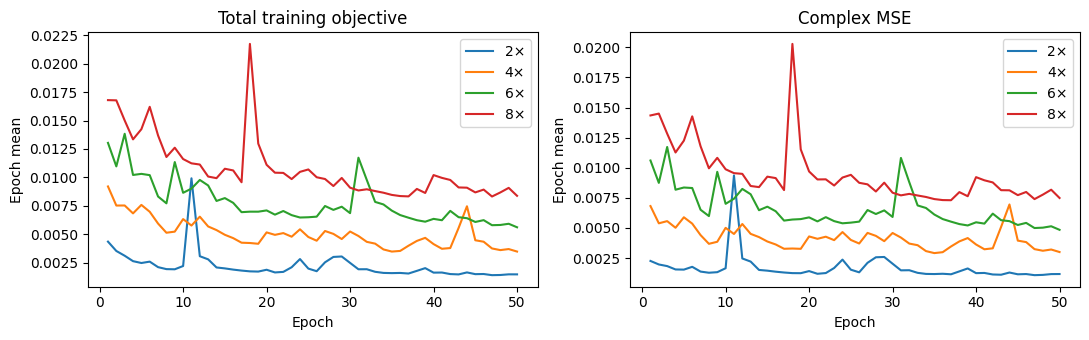

Rate,Final loss,Final complex MSE
2×,0.001469,0.001172
4×,0.003475,0.002998
6×,0.005610,0.004843
8×,0.008378,0.007487


In [2]:
pattern = re.compile(
    r'epoch_complete=(\d+)/\d+ step=(\d+) mean_loss=([0-9.eE+-]+) '
    r'mean_complex_mse=([0-9.eE+-]+) mean_l2_regularization=([0-9.eE+-]+)'
)
def training_records(run):
    records = [match.groups() for line in (run/'train.log').read_text().splitlines()
               if (match := pattern.search(line))]
    by_epoch = {int(row[0]): row for row in records}
    return [by_epoch[epoch] for epoch in sorted(by_epoch)]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
final_training = []
for rate in RATES:
    records = training_records(RUNS[rate])
    epochs = np.array([int(row[0]) for row in records])
    loss = np.array([float(row[2]) for row in records])
    complex_mse = np.array([float(row[3]) for row in records])
    axes[0].plot(epochs, loss, label=f'{rate}×')
    axes[1].plot(epochs, complex_mse, label=f'{rate}×')
    final_training.append({'Rate': f'{rate}×', 'Final loss': loss[-1],
                           'Final complex MSE': complex_mse[-1]})
axes[0].set(xlabel='Epoch', ylabel='Epoch mean', title='Total training objective'); axes[0].legend()
axes[1].set(xlabel='Epoch', ylabel='Epoch mean', title='Complex MSE'); axes[1].legend()
plt.tight_layout(); plt.show()
show_table(final_training, [(key, key) for key in final_training[0]], precision=6)

## Validation checkpoint selection

Rate,Selected epoch,Step,Validation PSNR,Validation SSIM,Validation NMSE
2×,40,7760,40.5674,0.9599,0.0050
4×,50,9700,35.7744,0.9181,0.0131
6×,50,9700,33.0766,0.8873,0.0226
8×,50,9700,30.2048,0.8495,0.0406


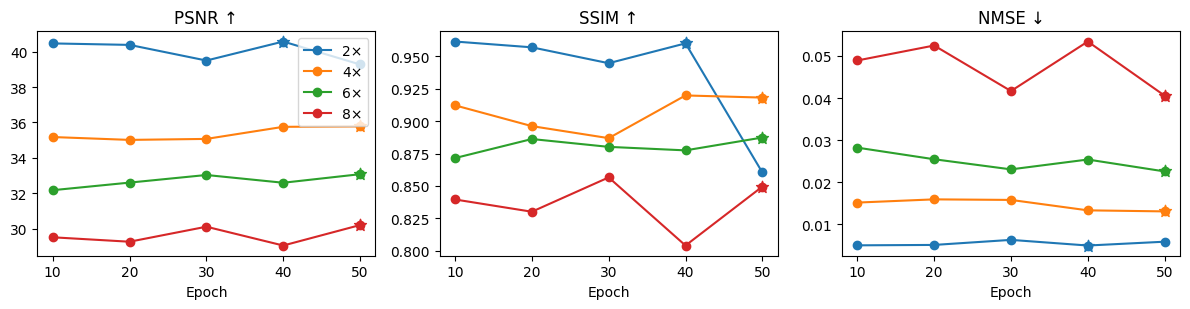

Stars mark the independently selected maximum-PSNR checkpoint for each rate.


In [3]:
selected = [{'Rate': f'{rate}×', 'Selected epoch': selections[rate]['completed_epochs'],
             'Step': selections[rate]['checkpoint_step'],
             'Validation PSNR': selections[rate]['validation_metrics']['psnr'],
             'Validation SSIM': selections[rate]['validation_metrics']['ssim'],
             'Validation NMSE': selections[rate]['validation_metrics']['nmse']}
            for rate in RATES]
show_table(selected, [(key, key) for key in selected[0]])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for rate in RATES:
    candidates = selections[rate]['candidates']
    for axis, key, title in zip(axes, ['psnr', 'ssim', 'nmse'], ['PSNR ↑', 'SSIM ↑', 'NMSE ↓']):
        axis.plot([row['completed_epochs'] for row in candidates],
                  [row['cascade_cnn'][key] for row in candidates], marker='o', label=f'{rate}×')
        axis.scatter([selections[rate]['completed_epochs']],
                     [selections[rate]['validation_metrics'][key]], marker='*', s=80)
        axis.set(xlabel='Epoch', title=title)
axes[0].legend()
plt.tight_layout(); plt.show()
print('Stars mark the independently selected maximum-PSNR checkpoint for each rate.')

## Held-out test results across acceleration rates

Rate,Selected epoch,ZF PSNR,Cascade PSNR,PSNR gain,ZF SSIM,Cascade SSIM,Cascade NMSE,Residual,Seconds/slice
2×,40,35.9877,40.1660,4.1784,0.9304,0.9538,0.0162,0.1959,0.0381
4×,50,29.7164,35.2762,5.5597,0.8295,0.9080,0.0422,0.1454,0.1501
6×,50,26.8159,32.0217,5.2058,0.7736,0.8703,0.0622,0.1279,0.0384
8×,50,25.3353,30.5205,5.1852,0.7441,0.8464,0.0878,0.1130,0.0281


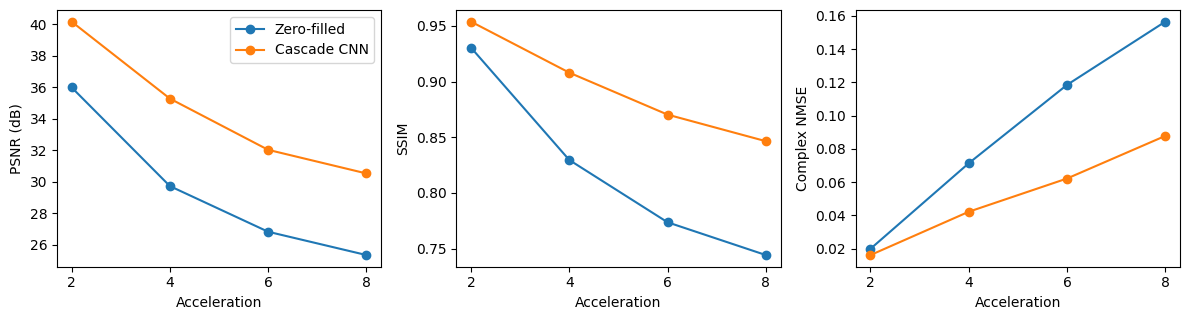

In [4]:
rate_results = []
for rate in RATES:
    baseline, result = tests[rate]['zero_filled'], tests[rate]['cascade_cnn']
    rate_results.append({
        'Rate': f'{rate}×', 'Selected epoch': selections[rate]['completed_epochs'],
        'ZF PSNR': baseline['psnr'], 'Cascade PSNR': result['psnr'],
        'PSNR gain': result['psnr']-baseline['psnr'],
        'ZF SSIM': baseline['ssim'], 'Cascade SSIM': result['ssim'],
        'Cascade NMSE': result['nmse'], 'Residual': result['measurement_residual'],
        'Seconds/slice': result['seconds_per_slice']})
show_table(rate_results, [(key, key) for key in rate_results[0]])

x = np.array(RATES)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for axis, key, ylabel in [
    (axes[0], 'psnr', 'PSNR (dB)'),
    (axes[1], 'ssim', 'SSIM'),
    (axes[2], 'nmse', 'Complex NMSE')]:
    axis.plot(x, [tests[r]['zero_filled'][key] for r in RATES], marker='o', label='Zero-filled')
    axis.plot(x, [tests[r]['cascade_cnn'][key] for r in RATES], marker='o', label='Cascade CNN')
    axis.set(xlabel='Acceleration', ylabel=ylabel, xticks=x)
axes[0].legend()
plt.tight_layout(); plt.show()

## Detailed 4× baseline comparison

In [5]:
comparison = []
for name, values in [
    ('Zero-filled', test['zero_filled']), ('MoDL', modl['modl']),
    ('RDBM', rdbm['rdbm']), ('Unrolled RDBM', unrolled['unrolled_rdbm']),
    ('Cascade CNN', test['cascade_cnn'])
]:
    comparison.append({'Method': name, 'PSNR ↑': values['psnr'], 'SSIM ↑': values['ssim'],
                       'Complex NMSE ↓': values['nmse'], 'Residual ↓': values['measurement_residual'],
                       'Seconds/slice ↓': values.get('seconds_per_slice', np.nan)})
show_table(comparison, [(key, key) for key in comparison[0]],
           bold_best={'PSNR ↑':'max', 'SSIM ↑':'max', 'Complex NMSE ↓':'min',
                      'Residual ↓':'min', 'Seconds/slice ↓':'min'})

result = test['cascade_cnn']; baseline = test['zero_filled']
print(f"Cascade vs zero-filled: {result['psnr']-baseline['psnr']:+.2f} dB PSNR, "
      f"{result['ssim']-baseline['ssim']:+.4f} SSIM, and "
      f"{100*(1-result['nmse']/baseline['nmse']):.1f}% lower complex NMSE.")
print(f"Cascade vs RDBM: {result['psnr']-rdbm['rdbm']['psnr']:+.2f} dB PSNR and "
      f"{100*(1-result['nmse']/rdbm['rdbm']['nmse']):.1f}% lower complex NMSE.")

Method,PSNR ↑,SSIM ↑,Complex NMSE ↓,Residual ↓,Seconds/slice ↓
Zero-filled,29.7164,0.8295,0.0714,0.1622,nan
MoDL,34.8049,0.8024,0.1104,0.1474,0.0538
RDBM,35.6007,0.9207,0.0559,0.1450,0.1916
Unrolled RDBM,36.3693,0.9088,0.0406,0.1487,0.0696
Cascade CNN,35.2762,0.9080,0.0422,0.1454,0.1501


Cascade vs zero-filled: +5.56 dB PSNR, +0.0785 SSIM, and 40.8% lower complex NMSE.
Cascade vs RDBM: -0.32 dB PSNR and 24.5% lower complex NMSE.


## 4× results by acquisition

Acquisition,Volumes,ZF PSNR,Cascade PSNR,ZF SSIM,Cascade SSIM,ZF NMSE,Cascade NMSE
AXFLAIR,2,28.5068,32.3610,0.7856,0.8481,0.1538,0.1854
AXT1POST,10,29.9895,35.6180,0.8333,0.9156,0.0560,0.0189
AXT1PRE,2,29.5610,36.4825,0.8545,0.9296,0.0655,0.0158


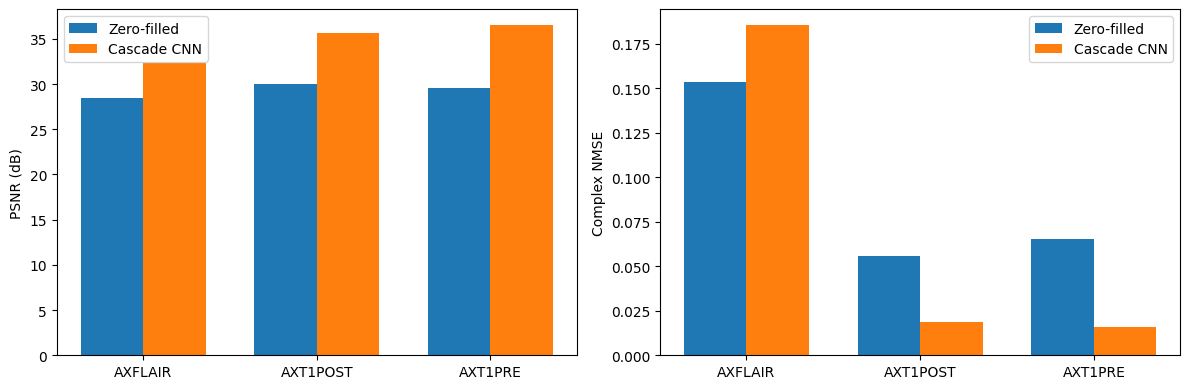

In [6]:
acquisition = []
for name, group in test['by_acquisition'].items():
    acquisition.append({'Acquisition': name, 'Volumes': group['volume_count'],
        'ZF PSNR': group['zero_filled']['psnr'], 'Cascade PSNR': group['cascade_cnn']['psnr'],
        'ZF SSIM': group['zero_filled']['ssim'], 'Cascade SSIM': group['cascade_cnn']['ssim'],
        'ZF NMSE': group['zero_filled']['nmse'], 'Cascade NMSE': group['cascade_cnn']['nmse']})
show_table(acquisition, [(key, key) for key in acquisition[0]])

x=np.arange(len(acquisition)); width=.36
fig, axes=plt.subplots(1,2,figsize=(12,4))
axes[0].bar(x-width/2,[row['ZF PSNR'] for row in acquisition],width,label='Zero-filled')
axes[0].bar(x+width/2,[row['Cascade PSNR'] for row in acquisition],width,label='Cascade CNN')
axes[0].set_xticks(x,[row['Acquisition'] for row in acquisition]); axes[0].set_ylabel('PSNR (dB)'); axes[0].legend()
axes[1].bar(x-width/2,[row['ZF NMSE'] for row in acquisition],width,label='Zero-filled')
axes[1].bar(x+width/2,[row['Cascade NMSE'] for row in acquisition],width,label='Cascade CNN')
axes[1].set_xticks(x,[row['Acquisition'] for row in acquisition]); axes[1].set_ylabel('Complex NMSE'); axes[1].legend()
plt.tight_layout(); plt.show()

## 4× reconstruction across cascades

The example is selected automatically as the test slice closest to the median
Cascade CNN PSNR gain. Image and error scales are shared across columns. The RDBM
output uses a fixed random seed for reproducibility.

Sample: file_brain_AXT1POST_200_6002386:10 (index 42)


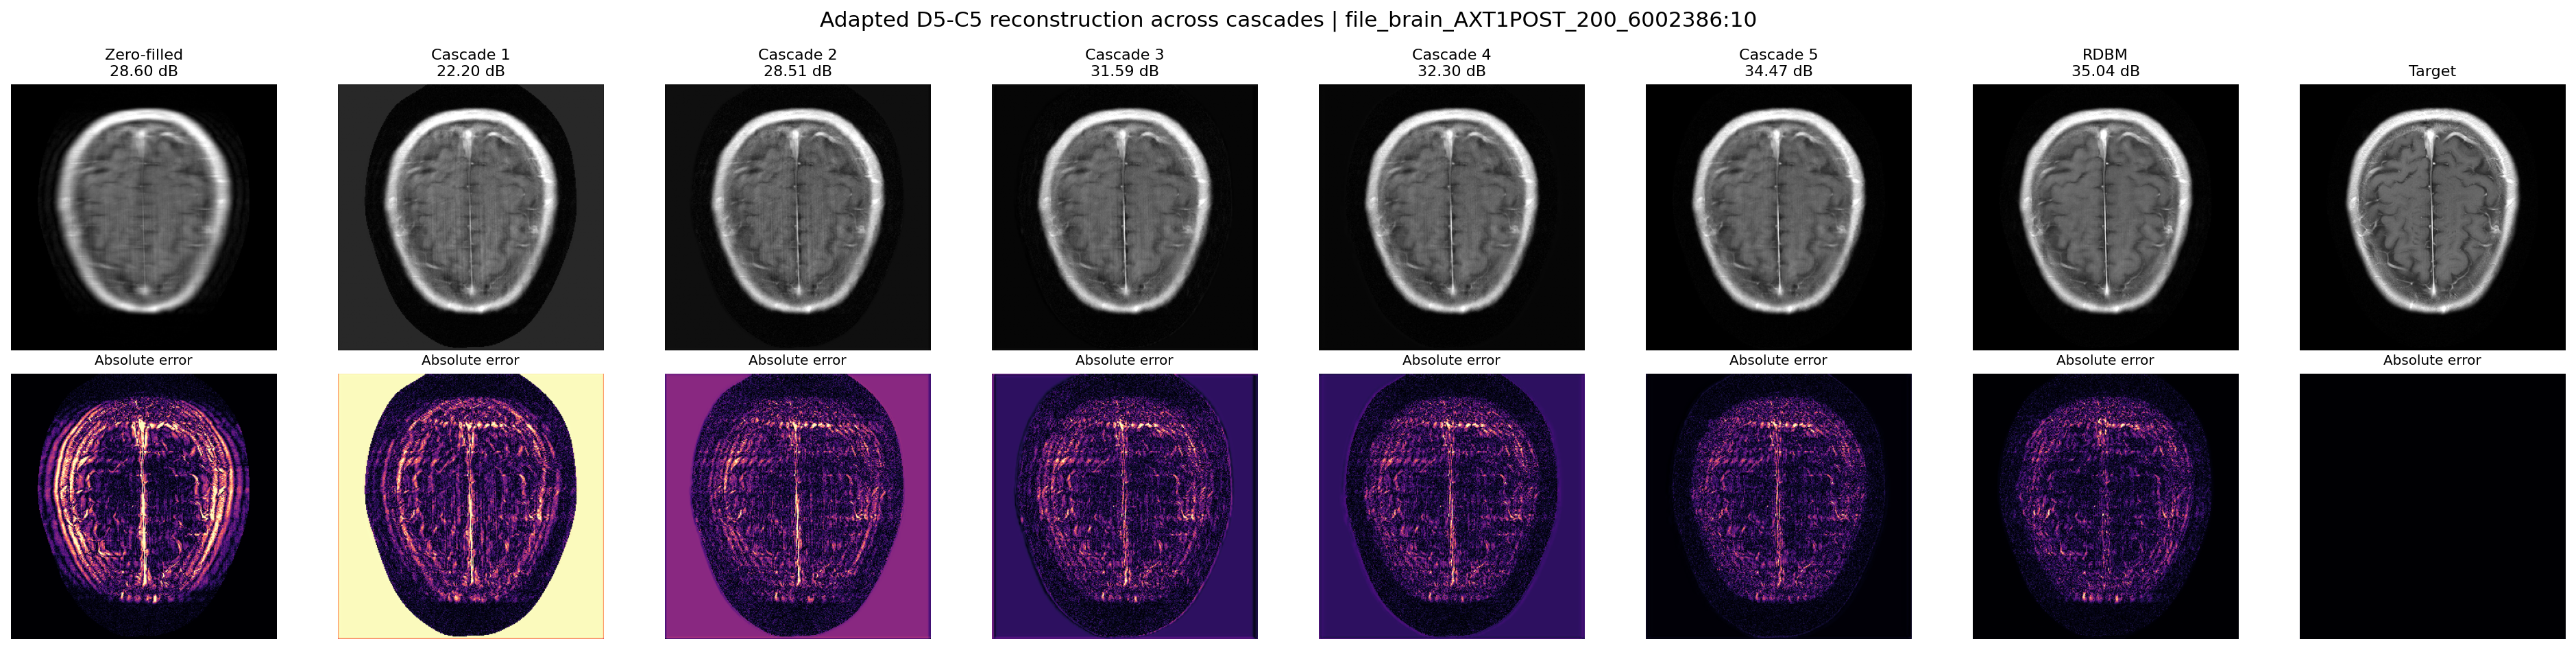

State,PSNR,SSIM,NMSE
Zero-filled,28.6018,0.8144,0.0333
Cascade 1,22.2035,0.5071,0.1110
Cascade 2,28.5061,0.5178,0.0309
Cascade 3,31.5882,0.5951,0.0182
Cascade 4,32.3026,0.6239,0.0151
Cascade 5,34.4731,0.9147,0.0102
RDBM,35.0371,0.9287,0.0091


In [7]:
print(f"Sample: {progression['sample_id']} (index {progression['sample_index']})")
display(Image(filename=str(ROOT/'results/cascade_cnn_evaluation/qualitative/cascade_progression.png'), width=2400))
metric_rows=[{'State':name,'PSNR':values['psnr'],'SSIM':values['ssim'],'NMSE':values['nmse']}
             for name,values in progression['metrics'].items()]
show_table(metric_rows, [(key,key) for key in metric_rows[0]])

## Interpretation

- Independently trained Cascade CNN models improve PSNR and SSIM over zero-filled
  reconstruction at every acceleration rate.
- Test PSNR is 40.17, 35.28, 32.02, and 30.52 dB at 2×, 4×, 6×, and 8×,
  respectively. Quality decreases as fewer phase-encoding lines are retained.
- Validation selected epoch 40 for 2× and epoch 50 for 4×, 6×, and 8×.
- The detailed 4× comparison remains below the original RDBM in PSNR and SSIM,
  while producing lower complex NMSE.
- Timing is descriptive and should be remeasured in isolated repeated runs before
  making formal speed claims.

## Reproducibility artifacts

In [8]:
artifacts = []
for rate in RATES:
    artifacts.extend([
        {'Rate':f'{rate}×','Artifact':'Selected checkpoint','Path':selections[rate]['checkpoint']},
        {'Rate':f'{rate}×','Artifact':'Checkpoint selection','Path':str(RUNS[rate]/'evaluation/best_validation_checkpoint.json')},
        {'Rate':f'{rate}×','Artifact':'Test summary','Path':str(test_dirs[rate]/'summary.json')},
        {'Rate':f'{rate}×','Artifact':'Test slice metrics','Path':str(test_dirs[rate]/'slice_metrics.jsonl')},
        {'Rate':f'{rate}×','Artifact':'Training log','Path':str(RUNS[rate]/'train.log')},
    ])
show_table(artifacts, [('Rate','Rate'),('Artifact','Artifact'),('Path','Path')], precision=0)

Rate,Artifact,Path
2×,Selected checkpoint,/data/david_agyei/nyu-dataset/derived/multicoil_cascade_cnn_2x/checkpoint-epoch-040-step-0007760.pt
2×,Checkpoint selection,/data/david_agyei/nyu-dataset/derived/multicoil_cascade_cnn_2x/evaluation/best_validation_checkpoint.json
2×,Test summary,/data/david_agyei/nyu-dataset/derived/multicoil_cascade_cnn_2x/evaluation/test/step-0007760/summary.json
2×,Test slice metrics,/data/david_agyei/nyu-dataset/derived/multicoil_cascade_cnn_2x/evaluation/test/step-0007760/slice_metrics.jsonl
2×,Training log,/data/david_agyei/nyu-dataset/derived/multicoil_cascade_cnn_2x/train.log
4×,Selected checkpoint,/data/david_agyei/nyu-dataset/derived/multicoil_cascade_cnn_4x/checkpoint-epoch-050-step-0009700.pt
4×,Checkpoint selection,/data/david_agyei/nyu-dataset/derived/multicoil_cascade_cnn_4x/evaluation/best_validation_checkpoint.json
4×,Test summary,/data/david_agyei/nyu-dataset/derived/multicoil_cascade_cnn_4x/evaluation/test/step-0009700/summary.json
4×,Test slice metrics,/data/david_agyei/nyu-dataset/derived/multicoil_cascade_cnn_4x/evaluation/test/step-0009700/slice_metrics.jsonl
4×,Training log,/data/david_agyei/nyu-dataset/derived/multicoil_cascade_cnn_4x/train.log
